# Chronoamperometry (CA) Quickstart

Run all cells (`Runtime -> Run all` in Google Colab) to simulate a potential-step experiment, compare it against the exact Cottrell equation, and extract the diffusion coefficient $D$.

## 1. Setup

If running in Google Colab, uncomment and run the `pip install` line below.

In [1]:
# !pip install -q softpotato

import matplotlib.pyplot as plt
import numpy as np

import softpotato as sp
from softpotato import analytical as spa
from softpotato.reactions import Species
from softpotato.techniques import Chronoamperometry, plot_result, simulate

print(f"Soft Potato version: {sp.__version__}")

Soft Potato version: 3.4.0


## 2. Physical Parameters

Edit only the values in this cell to match your experiment (SI units: $\text{m}^2/\text{s}$, $\text{mol/m}^3 = \text{mM}$, $\text{V}$, $\text{s}$).

In [2]:
E0 = 0.0         # Formal potential [V]
E_step = -0.4    # Step potential [V] (well below E0 for diffusion control)
duration = 5.0   # Step duration [s]
D = 1.0e-9       # Diffusion coefficient [m^2/s] (= 1.0e-5 cm^2/s)
c_bulk = 1.0     # Bulk concentration [mol/m^3] (= 1.0 mM)
n = 1            # Electrons transferred

## 3. Run the Simulation

`simulate()` automatically builds an adaptive mesh and solves the diffusion PDE.

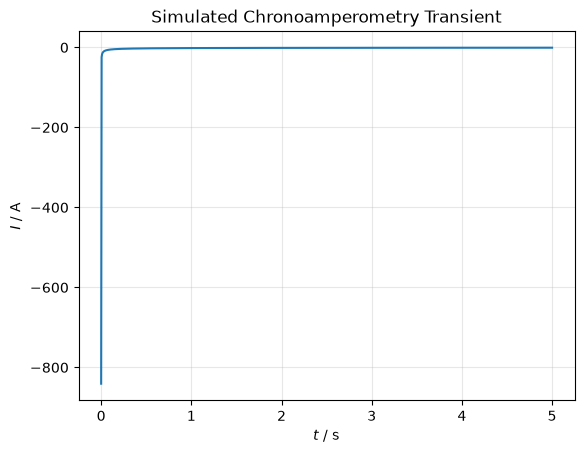

In [3]:
ox = Species("Ox", diffusivity=D, bulk_concentration=c_bulk, standard_potential=E0, n_electrons=n)
red = Species("Red", diffusivity=D, bulk_concentration=0.0)

ca = Chronoamperometry(E_step=E_step, duration=duration)
result = simulate(ca, [ox, red])

fig, ax = plot_result(result)
ax.set_title("Simulated Chronoamperometry Transient")
plt.show()

## 4. Compare Against the Exact Cottrell Equation

For a large overpotential step at a planar electrode, the simulated current density should match `softpotato.analytical.cottrell()`.

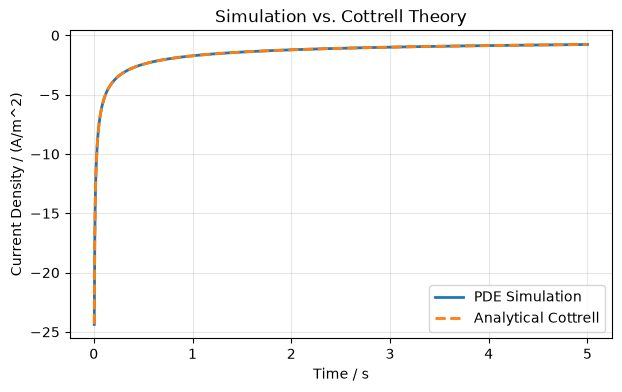

In [4]:
t = result.time[1:]  # exclude t = 0 singularity
i_sim = result.current[1:]
# Note: simulate() returns current density [A/m^2] (area = 1.0 m^2)
i_cottrell = -spa.cottrell(t, n=n, D=D, c_bulk=c_bulk, area=1.0)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t, i_sim, label="PDE Simulation", lw=2)
ax.plot(t, i_cottrell, "--", label="Analytical Cottrell", lw=2)
ax.set(xlabel="Time / s", ylabel="Current Density / (A/m^2)", title="Simulation vs. Cottrell Theory")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## 5. Fit $D$ from the Transient

We can recover $D$ directly using `fit_cottrell()`.

In [5]:
fit = spa.fit_cottrell(t, np.abs(i_sim), n=n, area=1.0, c_bulk=c_bulk)
ci = fit.confidence_intervals["D"]
print(f"Fitted D = {fit.d:.4e} m^2/s (true: {D:.4e} m^2/s)")
print(f"95% CI   = [{ci[0]:.4e}, {ci[1]:.4e}] m^2/s")
print(f"R^2      = {fit.r_squared:.6f}")

Fitted D = 1.0008e-09 m^2/s (true: 1.0000e-09 m^2/s)
95% CI   = [1.0007e-09, 1.0008e-09] m^2/s
R^2      = 1.000000
